# Simulating Quantum Errors
### 0th Review — Quantum Error Correction for Radiation-Induced Noise in Satellite Quantum Communication Systems

**Scope of this notebook:** this covers the *noise simulation* stage only — modeling how
Bit-Flip, Depolarizing, and Amplitude Damping noise (the radiation-inspired error channels
identified in the project) corrupt a qubit's state at varying probabilities, and quantifying
that corruption using fidelity and physical error rate.

**Not in scope yet:** the 3-qubit Bit-Flip / Phase-Flip *correction* codes, logical error rate,
and pseudo-threshold analysis — these build directly on top of this notebook in the next review.


## 1. Setup

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, state_fidelity
from qiskit.visualization import plot_histogram

from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel,
    pauli_error,
    depolarizing_error,
    amplitude_damping_error,
)

plt.rcParams["figure.dpi"] = 110
np.random.seed(42)


## 2. Reference Quantum States

Three reference single-qubit states are used, matching Step 1 of the project methodology:

| Label | State | Circuit |
|---|---|---|
| `0` | \|0⟩ | (identity) |
| `1` | \|1⟩ | X |
| `+` | \|+⟩ | H |


In [11]:
def prepare_state(label: str) -> QuantumCircuit:
    """Return a 1-qubit circuit preparing the reference state |0>, |1>, or |+>."""
    qc = QuantumCircuit(1)
    if label == "1":
        qc.x(0)
    elif label == "+":
        qc.h(0)
    elif label != "0":
        raise ValueError(f"Unknown state label: {label}")
    return qc


TEST_STATES = ["0", "1", "+"]

for label in TEST_STATES:
    sv = Statevector(prepare_state(label))
    print(f"|{label}>  ->  {sv.data.round(3)}")


|0>  ->  [1.+0.j 0.+0.j]
|1>  ->  [0.+0.j 1.+0.j]
|+>  ->  [0.707+0.j 0.707+0.j]


## 3. Modeling Radiation-Induced Noise Channels

Each noise channel is attached to an idle (`id`) gate placed *after* state preparation.
This represents a qubit sitting in storage/transit while radiation strikes it — the
state-preparation gates themselves stay noiseless, which keeps the noise measured here
attributable only to the disturbance being modeled, not to gate imperfection.

- **Bit-Flip noise** — applies an X error with probability `p` (§6.1)
- **Depolarizing noise** — randomly applies X, Y, or Z with total probability `p` (§6.2)
- **Amplitude Damping noise** — models energy relaxation, decaying \|1⟩ → \|0⟩ with probability `gamma` (§6.3)


In [12]:
def bit_flip_noise_model(p: float) -> NoiseModel:
    error = pauli_error([("X", p), ("I", 1 - p)])
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(error, ["id"])
    return nm


def depolarizing_noise_model(p: float) -> NoiseModel:
    error = depolarizing_error(p, 1)
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(error, ["id"])
    return nm


def amplitude_damping_noise_model(gamma: float) -> NoiseModel:
    error = amplitude_damping_error(gamma)
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(error, ["id"])
    return nm


NOISE_BUILDERS = {
    "Bit-Flip": bit_flip_noise_model,
    "Depolarizing": depolarizing_noise_model,
    "Amplitude Damping": amplitude_damping_noise_model,
}


## 4. Sanity Check — What Does Noise Actually Do to a Qubit?

Before sweeping across probabilities, a single example makes the effect concrete: prepare
\|0⟩, apply 30% Bit-Flip noise, measure 2000 shots, and compare against the noiseless case.


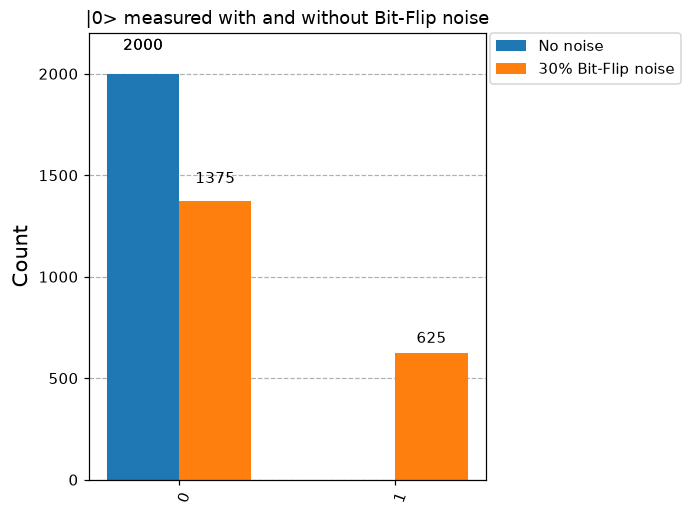

In [13]:
demo_qc = prepare_state("0")
demo_qc.id(0)
demo_qc.measure_all()

noiseless_sim = AerSimulator()
noisy_sim = AerSimulator(noise_model=bit_flip_noise_model(0.30))

counts_ideal = noiseless_sim.run(demo_qc, shots=2000).result().get_counts()
counts_noisy = noisy_sim.run(demo_qc, shots=2000).result().get_counts()

plot_histogram(
    [counts_ideal, counts_noisy],
    legend=["No noise", "30% Bit-Flip noise"],
    title="|0> measured with and without Bit-Flip noise",
)


## 5. Noise Sweep — Fidelity vs Noise Probability

For every (noise type, reference state, probability) combination:

1. Prepare the reference state
2. Apply the noise channel on an idle gate
3. Simulate the resulting **density matrix** (`save_density_matrix`, no measurement collapse)
4. Compute **fidelity** against the ideal statevector (§12.3)

Probabilities sweep from 0% to 50%, covering the low-noise regime the project expects to see
low logical error rates in, up through more severe noise.


In [14]:
PROBS = [0.0, 0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]

def simulate_fidelity(state_label: str, noise_name: str, p: float) -> float:
    qc = prepare_state(state_label)
    qc.id(0)
    qc.save_density_matrix()

    noise_model = NOISE_BUILDERS[noise_name](p)
    sim = AerSimulator(method="density_matrix", noise_model=noise_model)
    result = sim.run(qc).result()
    noisy_dm = result.data(0)["density_matrix"]

    ideal_sv = Statevector(prepare_state(state_label))
    return state_fidelity(ideal_sv, noisy_dm)


records = []
for noise_name in NOISE_BUILDERS:
    for state_label in TEST_STATES:
        for p in PROBS:
            fid = simulate_fidelity(state_label, noise_name, p)
            records.append(
                {"noise_type": noise_name, "state": f"|{state_label}>", "p": p, "fidelity": fid}
            )

results_df = pd.DataFrame(records)
results_df.head(10)


,noise_type,state,p,fidelity
0,Bit-Flip,|0>,0.00,1.00
1,Bit-Flip,|0>,0.01,0.99
2,Bit-Flip,|0>,0.02,0.98
3,Bit-Flip,|0>,0.05,0.95
4,Bit-Flip,|0>,0.10,0.90
5,Bit-Flip,|0>,0.15,0.85
6,Bit-Flip,|0>,0.20,0.80
7,Bit-Flip,|0>,0.30,0.70
8,Bit-Flip,|0>,0.40,0.60
9,Bit-Flip,|0>,0.50,0.50


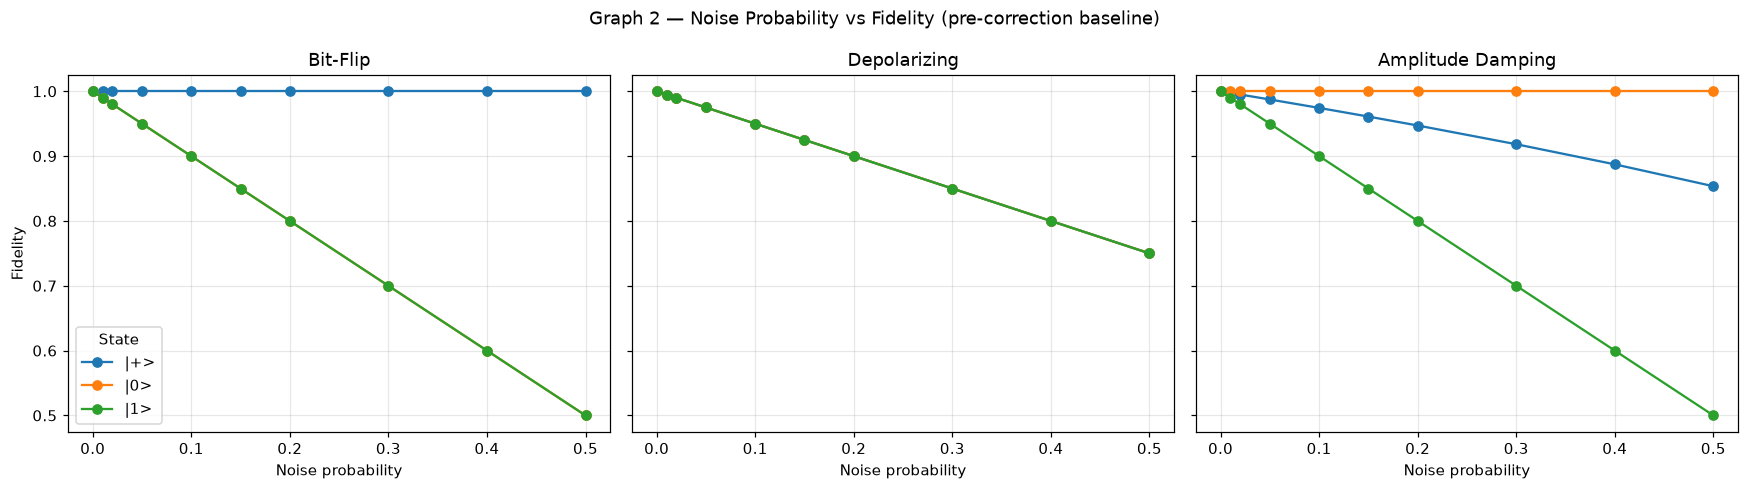

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, noise_name in zip(axes, NOISE_BUILDERS):
    subset = results_df[results_df.noise_type == noise_name]
    for state_label, group in subset.groupby("state"):
        ax.plot(group.p, group.fidelity, marker="o", label=state_label)
    ax.set_title(noise_name)
    ax.set_xlabel("Noise probability")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Fidelity")
axes[0].legend(title="State")
fig.suptitle("Graph 2 — Noise Probability vs Fidelity (pre-correction baseline)")
fig.tight_layout()
fig.savefig("fidelity_vs_noise_probability.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Physical Error Rate Validation (§12.1)

The **physical error rate** is the probability a qubit experiences an error *before* any
correction is applied. As a check that the injected noise behaves as intended, \|0⟩ is
measured over many shots under Bit-Flip noise at each probability, and the simulated flip
fraction is compared against the theoretical value `p`.


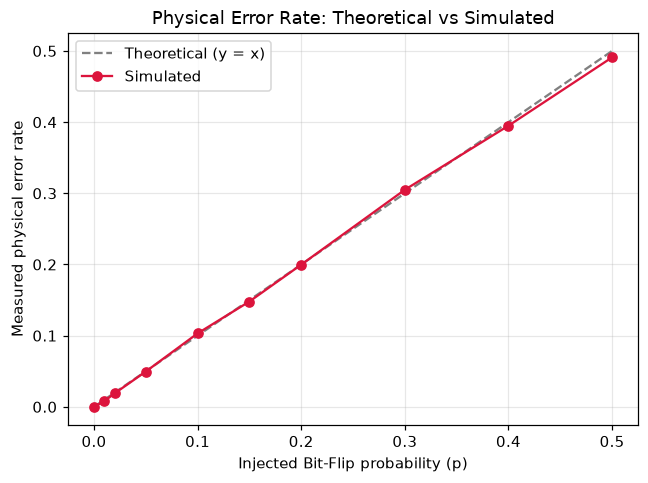

,p_theoretical,p_simulated
0,0.00,0.0000
1,0.01,0.0080
2,0.02,0.0190
3,0.05,0.0496
4,0.10,0.1032
5,0.15,0.1480
6,0.20,0.1998
7,0.30,0.3050
8,0.40,0.3950
9,0.50,0.4910


In [16]:
SHOTS = 5000
rate_records = []

for p in PROBS:
    qc = prepare_state("0")
    qc.id(0)
    qc.measure_all()

    sim = AerSimulator(noise_model=bit_flip_noise_model(p))
    counts = sim.run(qc, shots=SHOTS).result().get_counts()
    flipped = counts.get("1", 0) / SHOTS

    rate_records.append({"p_theoretical": p, "p_simulated": flipped})

rate_df = pd.DataFrame(rate_records)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(rate_df.p_theoretical, rate_df.p_theoretical, "--", color="gray", label="Theoretical (y = x)")
ax.plot(rate_df.p_theoretical, rate_df.p_simulated, "o-", color="crimson", label="Simulated")
ax.set_xlabel("Injected Bit-Flip probability (p)")
ax.set_ylabel("Measured physical error rate")
ax.set_title("Physical Error Rate: Theoretical vs Simulated")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("physical_error_rate_validation.png", dpi=150, bbox_inches="tight")
plt.show()

rate_df


## 7. Observations

- **Fidelity decreases as noise probability increases** across all three channels, confirming
  the expected trend from the project's Expected Results (§14.1–14.3).
- **Bit-Flip noise leaves \|+⟩ unaffected** — an X error commutes with \|+⟩, so fidelity stays
  at 1.0 regardless of `p`. This is exactly the blind spot the *Phase-Flip* code exists to cover.
- **Amplitude Damping is asymmetric** — \|0⟩ is a fixed point (fidelity stays 1.0) while \|1⟩
  decays steadily, matching the "energy loss" interpretation in §6.3.
- **Depolarizing noise degrades all three states**, since it mixes in X, Y, and Z errors
  regardless of which state is stored.
- The simulated physical error rate tracks the theoretical injected probability closely,
  confirming the noise models are correctly calibrated before correction codes are layered on.

## 8. Next Steps

This notebook establishes the *uncorrected* baseline. The next review builds directly on it:

1. Implement the 3-qubit Bit-Flip and Phase-Flip repetition codes (§8–9)
2. Re-run this same noise sweep on the *encoded* states
3. Compare **logical error rate** against the **physical error rate** measured here
4. Identify the **pseudo-threshold** (§13) where the two curves cross


In [17]:
results_df.to_csv("noise_fidelity_results.csv", index=False)
rate_df.to_csv("physical_error_rate_results.csv", index=False)
print("Saved: noise_fidelity_results.csv, physical_error_rate_results.csv")


Saved: noise_fidelity_results.csv, physical_error_rate_results.csv
